In [1]:
import os
# https://stackoverflow.com/questions/20554074/sklearn-omp-error-15-initializing-libiomp5md-dll-but-found-mk2iomp5md-dll-a
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

import torch
from torch import nn

import numpy as np
import normflows as nf

import tqdm

import matplotlib.pyplot as plt

In [ ]:
import importlib
import sys
from pathlib import Path
if os.name == 'nt':
    sys.path.append(os.getcwd() + "\\..\\src")    
else:
    sys.path.append(os.getcwd() + "/../src")
print(sys.path)

['p:\\Programs\\miniconda3\\envs\\master-pytorch\\python313.zip', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\DLLs', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib', 'p:\\Programs\\miniconda3\\envs\\master-pytorch', '', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\win32', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\win32\\lib', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\Pythonwin', 'd:\\Studium\\Masters\\dev\\src']


In [5]:
import neural_net

importlib.reload(neural_net)

from neural_net import MLP

# TODOs

- Create a network (can copy mostly)
- Create an eval function
- Create function to get the jacobians


In [20]:
def transform_samples(model: MLP, x: torch.Tensor, inference_steps = 10, requires_grad = False):
    model.eval().requires_grad_(requires_grad)

    for i, t in enumerate(torch.linspace(0, 1, inference_steps, device = x.device), start=1):
        pred = model(x, t.expand(x.size(0)))
        x = x + (1 / inference_steps) * pred
        # x = model.ex_context.domain.wrap_torch(x)

    return x 

def vis_model(model, target, device, grid_size = 100, num_vis_samples = 10000):
    x = torch.rand((num_vis_samples, 2), device=device)
    y = transform_samples(model, x)
    ynp = y.cpu().detach().numpy()

    H, xedges, yedges = np.histogram2d(ynp[:, 0], ynp[:, 1], bins=grid_size)

    X, Y = np.meshgrid(torch.linspace(0, 1, grid_size), torch.linspace(0, 1, grid_size))

    # ---

    xx, yy = torch.meshgrid(torch.linspace(0, 1, grid_size), torch.linspace(0, 1, grid_size))
    zz = torch.cat([xx.unsqueeze(2), yy.unsqueeze(2)], 2).view(-1, 2)
    zz = zz.to(device)
    log_prob = target.log_prob(zz).to('cpu').view(*xx.shape)
    prob = torch.exp(log_prob)

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

    #jac = torch.func.vmap(torch.func.jacrev(model, chunk_size=1))
    #jac_matrices = jac(zz)
    #dets = torch.det(jac_matrices).abs().view(*xx.shape)


    ax1.pcolormesh(xx, yy, prob.data.numpy())
    ax1.set_title("target dist")

    ax2.pcolormesh(X, Y, H)
    ax2.set_title("model samples")

    #ax3.pcolormesh(xx, yy, dets.cpu().detach().numpy())
    #ax3.set_title("model jacobians")
    plt.show()

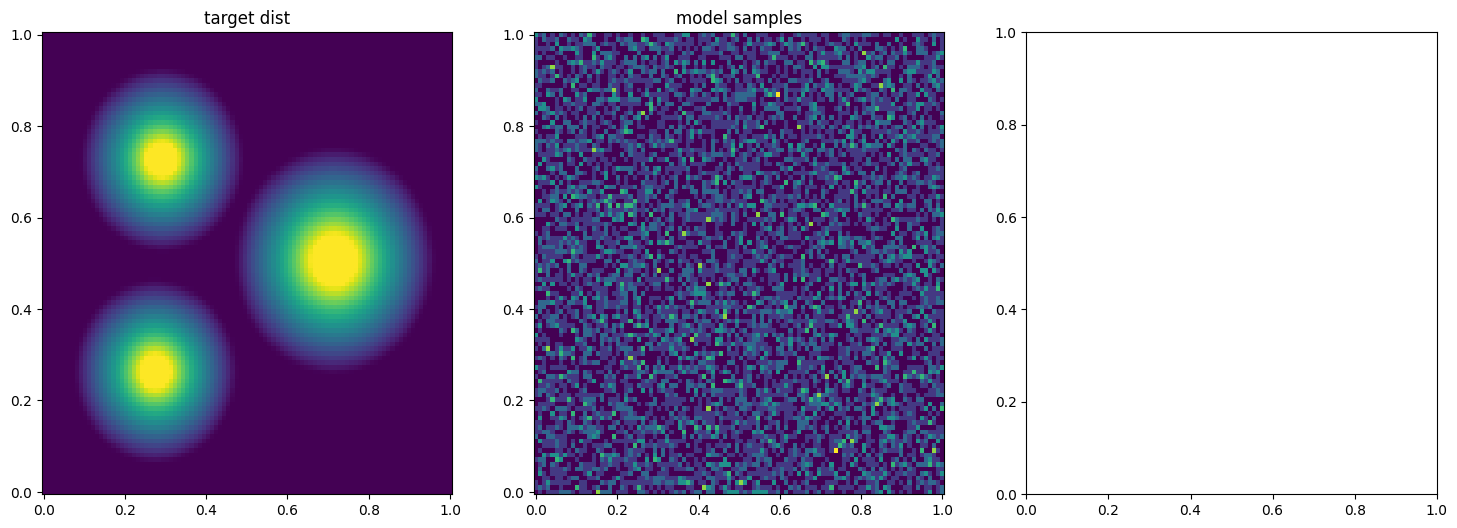

In [21]:
# img = plt.imread('assets/test_distributions/complex.png')
img = plt.imread('assets/test_distributions/TestTargetDist.png')
target = nf.distributions.ImagePrior(img, x_range=[0, 1], y_range=[0, 1])

model = MLP(channels_in=2, channels_out=2, channels_t=128, layers=[2, 16, 16, 16, 2], activation_function=nn.SiLU())

enable_cuda = True
device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')

target.to(device)
model.to(device)

vis_model(model, target, device)

In [ ]:
data = self.ex_context.target_dist.rejection_sample(self.train_context.batch_size)

scores = []
imgs = []



optim = torch.optim.AdamW(model.parameters(), lr=1e-4)

pbar = tqdm.tqdm(range(self.train_context.training_steps))
for i in pbar:
    for sample in data:
        sample = mcmc.MCMC_step(self.ex_context.target_dist, sample, 0.5, 0.1)

    x1 = torch.Tensor(data)
    x0 = torch.from_numpy(self.ex_context.input_dist.sample(len(x1))).type(torch.float32)

    target = self.ex_context.domain.dist_func_torch(x0, x1)

    t = torch.rand(x1.size(0))
    xt = x0 + t[:, None] * target

    pred = model(xt, t)
    loss = ((target - pred) ** 2).mean()
    loss.backward()
    optim.step()
    optim.zero_grad()
